# **QSAR Model Building of Acetylcholinesterase Inhibitors**

Chanin Nantasenamat

*Data Professor YouTube channel, http://youtube.com/dataprofessor*

# Read in data

In [2]:
import pandas as pd

In [3]:
! ls


bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv  sample_data


In [4]:
# Load your local KEAP1 bioactivity dataset
dataset_path = 'bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv'
dataset = pd.read_csv(dataset_path)

# Display the dataset
dataset


,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,PubchemFP9,...,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880,pIC50
0,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.568636
1,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,3.928118
2,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,7.481486
3,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.769551
4,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,7.698970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,8.113509
342,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.853872
343,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,7.508638
344,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.000000


In [5]:
X = dataset.drop(['pIC50'], axis=1)
X

,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,PubchemFP9,...,PubchemFP871,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880
0,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
342,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
343,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
344,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [6]:
Y = dataset.iloc[:,-1]
Y

,pIC50
0,5.568636
1,3.928118
2,7.481486
3,5.769551
4,7.698970
...,...
341,8.113509
342,5.853872
343,7.508638
344,5.000000


# Remove low variance features

In [7]:
from sklearn.feature_selection import VarianceThreshold

selection = VarianceThreshold(threshold=(.8 * (1 - .8)))
X_sel = selection.fit_transform(X)

selected = X.columns[selection.get_support()]
pd.Series(selected).to_csv("descriptor_list.csv", index=False, header=False)
X = pd.DataFrame(X_sel, columns=selected)

# ---- checks ----
print("Original:", len(selection.get_support()), "| Selected:", len(selected))
print("First 5 names:", list(selected[:5]))
print("Real PaDEL names:", all(c.startswith("PubchemFP") for c in selected))
print("X shape:", X.shape)

saved = pd.read_csv("descriptor_list.csv", header=None)[0].tolist()
print("Saved list OK:", saved == list(selected), "| entries:", len(saved))

Original: 881 | Selected: 138
First 5 names: ['PubchemFP0', 'PubchemFP1', 'PubchemFP2', 'PubchemFP13', 'PubchemFP16']
Real PaDEL names: True
X shape: (346, 138)
Saved list OK: True | entries: 138


In [8]:
# In the app, use the following to get this same descriptor list
# of 218 variables from the initial set of 881 variables
# Xlist = list(pd.read_csv('descriptor_list.csv').columns)
# X[Xlist]

# Gradient Boosting Regressor Model

In [9]:
import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.feature_selection import VarianceThreshold

# 1. LOAD DATA
data = pd.read_csv("bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv")
X = data[[c for c in data.columns if c.startswith("PubchemFP")]]
Y = data["pIC50"].values

# 2. FEATURE SELECTION (keeps real names, saves the name list)
selection = VarianceThreshold(threshold=0.8 * (1 - 0.8)).fit(X)
selected = X.columns[selection.get_support()]
pd.Series(selected).to_csv("descriptor_list.csv", index=False, header=False)
X = X[selected].values.astype(np.float64)

# 3. TRAIN WITH THE OPTIMIZED PARAMETERS
model = GradientBoostingRegressor(
    n_estimators=342,
    learning_rate=0.03504229766364686,
    loss="huber",
    max_depth=4,
    max_features="sqrt",
    min_samples_leaf=3,
    min_samples_split=8,
    subsample=0.7814540334239805,
    random_state=42,
)
model.fit(X, Y)

# 4. SAVE
joblib.dump(model, "Keap1.pkl", compress=3)
print("Saved Keap1.pkl | features:", model.n_features_in_)

Saved Keap1.pkl | features: 138


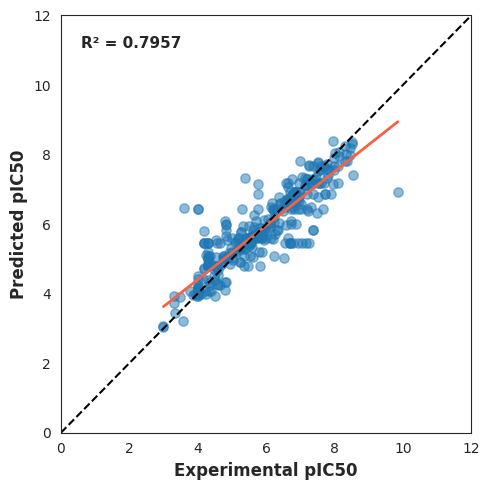

In [10]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import r2_score

# ==========================================
# 1. LOAD MODEL, FEATURES, AND TEST DATA
# ==========================================
# Load your trained model
model = joblib.load("Keap1.pkl")

# Load the exact feature names used during training
selected_features = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# TODO: Replace with your actual test dataframe or split logic
# data_test = pd.read_csv("your_test_data.csv")
data_test = pd.read_csv(
    "bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv"
)

# Align test data exactly with the trained model's expected features
X_test = data_test[selected_features].values.astype(np.float64)
Y_test = data_test["pIC50"].values

# ==========================================
# 2. PREDICTIONS
# ==========================================
Y_pred = model.predict(X_test)
r2 = r2_score(Y_test, Y_pred)

# ==========================================
# 3. REGRESSION PLOT
# ==========================================
sns.set_style("white")
plt.figure(figsize=(5, 5))

ax = sns.regplot(
    x=Y_test,
    y=Y_pred,
    scatter_kws={"alpha": 0.5, "s": 45},
    line_kws={"color": "#F56245", "linewidth": 2},
    ci=None,
)

# Identity line
plt.plot([0, 12], [0, 12], linestyle="--", linewidth=1.5, color="black")

ax.set_xlabel("Experimental pIC50", fontsize=12, fontweight="bold")
ax.set_ylabel("Predicted pIC50", fontsize=12, fontweight="bold")
ax.set_xlim(0, 12)
ax.set_ylim(0, 12)

ax.text(
    0.05,
    0.95,
    f"R² = {r2:.4f}",
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold",
    verticalalignment="top",
)

plt.tight_layout()
plt.savefig(
    "Optimized_Gradient_Boosting_Regression.png",
    dpi=600,
    bbox_inches="tight",
)
plt.show()


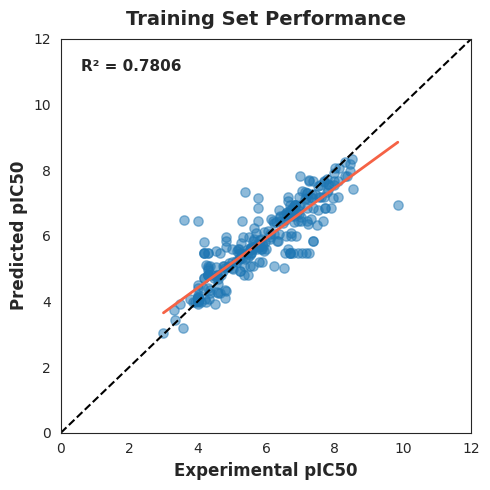

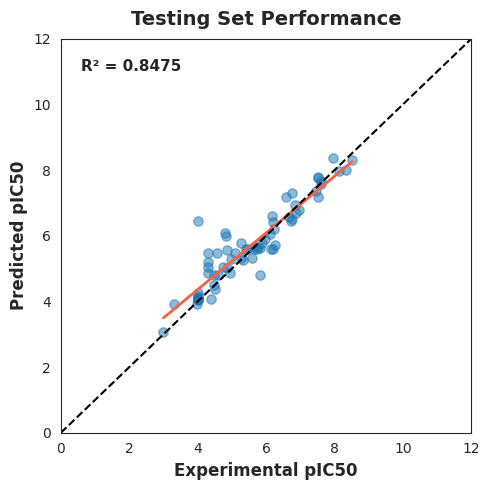

In [11]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

# ==========================================
# 1. LOAD MODEL AND FEATURES
# ==========================================
model = joblib.load("Keap1.pkl")
selected_features = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# Load original dataset
data = pd.read_csv(
    "bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv"
)

# Extract and align features/targets
X = data[selected_features].values.astype(np.float64)
Y = data["pIC50"].values

# Split exactly how you did before training (adjust test_size/random_state as needed)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)


# ==========================================
# 2. PLOTTING FUNCTION
# ==========================================
def plot_regression(Y_true, Y_pred, title, filename):
    r2 = r2_score(Y_true, Y_pred)

    sns.set_style("white")
    plt.figure(figsize=(5, 5))

    ax = sns.regplot(
        x=Y_true,
        y=Y_pred,
        scatter_kws={"alpha": 0.5, "s": 45},
        line_kws={"color": "#F56245", "linewidth": 2},
        ci=None,
    )

    # Identity line
    plt.plot([0, 12], [0, 12], linestyle="--", linewidth=1.5, color="black")

    ax.set_title(title, fontsize=14, fontweight="bold", pad=10)
    ax.set_xlabel("Experimental pIC50", fontsize=12, fontweight="bold")
    ax.set_ylabel("Predicted pIC50", fontsize=12, fontweight="bold")
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 12)

    ax.text(
        0.05,
        0.95,
        f"R² = {r2:.4f}",
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        verticalalignment="top",
    )

    plt.tight_layout()
    plt.savefig(filename, dpi=600, bbox_inches="tight")
    plt.show()


# ==========================================
# 3. GENERATE PREDICTIONS AND PLOTS
# ==========================================
# Train Set
Y_pred_train = model.predict(X_train)
plot_regression(
    Y_train,
    Y_pred_train,
    title="Training Set Performance",
    filename="Gradient_Boosting_Regression_TRAIN.png",
)

# Test Set
Y_pred_test = model.predict(X_test)
plot_regression(
    Y_test,
    Y_pred_test,
    title="Testing Set Performance",
    filename="Gradient_Boosting_Regression_TEST.png",
)


## Model Prediction

## Model Performance


--- Training Set Metrics ---
Mean squared error (MSE): 0.39
Coefficient of determination (R^2): 0.78


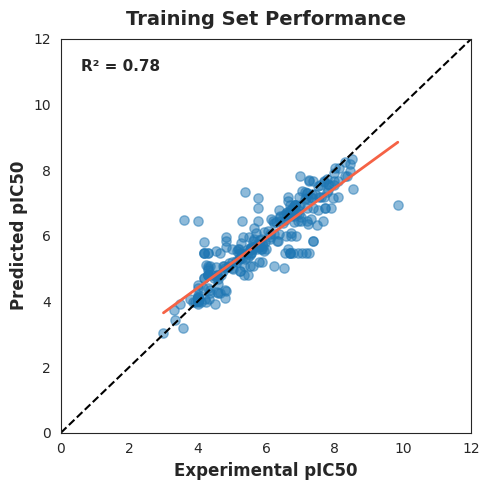


--- Testing Set Metrics ---
Mean squared error (MSE): 0.27
Coefficient of determination (R^2): 0.85


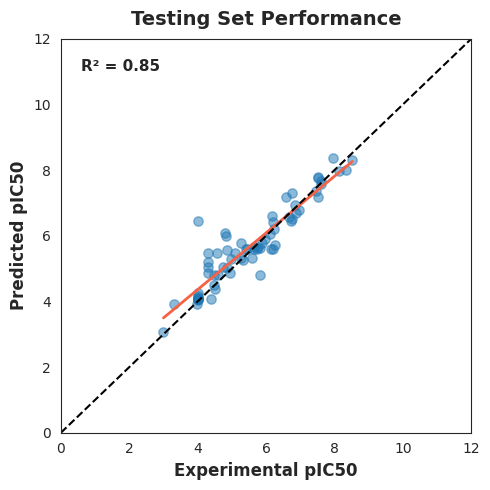

In [14]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# ==========================================
# 1. LOAD MODEL AND FEATURES
# ==========================================
model = joblib.load("Keap1.pkl")
selected_features = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# Load original dataset
data = pd.read_csv(
    "bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv"
)

# Extract and align features/targets
X = data[selected_features].values.astype(np.float64)
Y = data["pIC50"].values

# Split exactly how you did before training (adjust test_size/random_state as needed)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)


# ==========================================
# 2. PLOTTING AND EVALUATION FUNCTION
# ==========================================
def evaluate_and_plot(Y_true, Y_pred, set_label, filename):
    # Print metrics directly to console using your exact format
    print(f"\n--- {set_label} Metrics ---")
    print("Mean squared error (MSE): %.2f" % mean_squared_error(Y_true, Y_pred))
    print("Coefficient of determination (R^2): %.2f" % r2_score(Y_true, Y_pred))

    r2 = r2_score(Y_true, Y_pred)

    sns.set_style("white")
    plt.figure(figsize=(5, 5))

    ax = sns.regplot(
        x=Y_true,
        y=Y_pred,
        scatter_kws={"alpha": 0.5, "s": 45},
        line_kws={"color": "#F56245", "linewidth": 2},
        ci=None,
    )

    # Fixed Identity Line Coordinates
    plt.plot([0, 12], [0, 12], linestyle="--", linewidth=1.5, color="black")

    ax.set_title(f"{set_label} Performance", fontsize=14, fontweight="bold", pad=10)
    ax.set_xlabel("Experimental pIC50", fontsize=12, fontweight="bold")
    ax.set_ylabel("Predicted pIC50", fontsize=12, fontweight="bold")
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 12)

    ax.text(
        0.05,
        0.95,
        f"R² = {r2:.2f}",
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        verticalalignment="top",
    )

    plt.tight_layout()
    plt.savefig(filename, dpi=600, bbox_inches="tight")
    plt.show()


# ==========================================
# 3. RUN EVALUATION
# ==========================================
# Train Set
Y_pred_train = model.predict(X_train)
evaluate_and_plot(
    Y_train,
    Y_pred_train,
    set_label="Training Set",
    filename="Gradient_Boosting_Regression_TRAIN.png",
)

# Test Set
Y_pred_test = model.predict(X_test)
evaluate_and_plot(
    Y_test,
    Y_pred_test,
    set_label="Testing Set",
    filename="Gradient_Boosting_Regression_TEST.png",
)


# Data Visualization (Experimental vs Predicted pIC50 for Training Data)

In [15]:
import matplotlib.pyplot as plt
import numpy as np


--- Training Set Metrics ---
Mean squared error (MSE): 0.39
Coefficient of determination (R^2): 0.78
RMSE:                     0.6262
MAE:                      0.4146


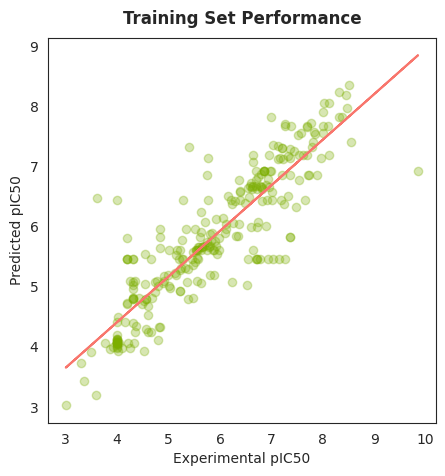


--- Testing Set Metrics ---
Mean squared error (MSE): 0.27
Coefficient of determination (R^2): 0.85
RMSE:                     0.5177
MAE:                      0.3377


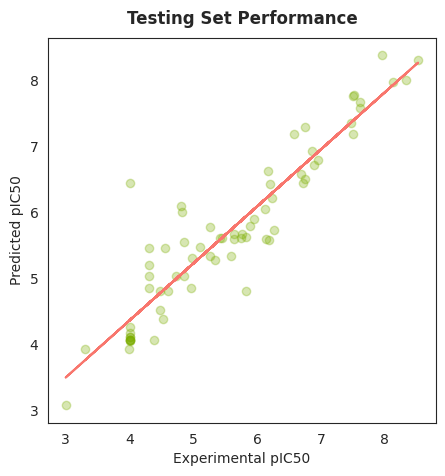

In [20]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# ==========================================
# 1. LOAD MODEL AND CURRENT FEATURES
# ==========================================
model = joblib.load("Keap1.pkl")
selected_features = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# Load original dataset
data = pd.read_csv(
    "bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv"
)

# Extract and align features/targets
X = data[selected_features].values.astype(np.float64)
Y = data["pIC50"].values

# Split data exactly how you did before training
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

Y_train = np.asarray(Y_train).ravel()
Y_test = np.asarray(Y_test).ravel()


# ==========================================
# 2. PLOTTING FUNCTION (YOUR DESIGN STYLE)
# ==========================================
def generate_styled_plot(Y_true, Y_pred, set_label, filename):
    # Print metrics directly to console using your preferred format
    print(f"\n--- {set_label} Metrics ---")
    print("Mean squared error (MSE): %.2f" % mean_squared_error(Y_true, Y_pred))
    print("Coefficient of determination (R^2): %.2f" % r2_score(Y_true, Y_pred))
    print(f"RMSE:                     {np.sqrt(mean_squared_error(Y_true, Y_pred)):.4f}")
    print(f"MAE:                      {mean_absolute_error(Y_true, Y_pred):.4f}")

    # Initialize your requested 5x5 layout
    plt.figure(figsize=(5, 5))

    # Scatter using your exact color and alpha settings
    plt.scatter(x=Y_true, y=Y_pred, c="#7CAE00", alpha=0.3)

    # Calculate trendline exactly as requested
    z = np.polyfit(Y_true, Y_pred, 1)
    p = np.poly1d(z)

    # Plot trendline using your specific red hex color
    plt.plot(Y_true, p(Y_true), "#F8766D")

    # Label formatting
    plt.ylabel('Predicted pIC50')
    plt.xlabel('Experimental pIC50')
    plt.title(f"{set_label} Performance", fontsize=12, fontweight="bold", pad=10)

    # Save the plot as a 600 DPI PNG image
    plt.savefig(filename, dpi=600, bbox_inches='tight')

    # Display the plot in the notebook
    plt.show()


# ==========================================
# 3. RUN EVALUATION FOR TRAIN & TEST
# ==========================================
# Train Set Predictions & Plots
Y_pred_train = model.predict(X_train)
generate_styled_plot(
    Y_train,
    Y_pred_train,
    set_label="Training Set",
    filename="keap1_experimental_vs_predicted_pIC50_TRAIN.png"
)

# Test Set Predictions & Plots
Y_pred_test = model.predict(X_test)
generate_styled_plot(
    Y_test,
    Y_pred_test,
    set_label="Testing Set",
    filename="keap1_experimental_vs_predicted_pIC50_TEST.png"
)



--- Training Set Metrics ---
Mean squared error (MSE): 0.39
Coefficient of determination (R^2): 0.78
RMSE:                     0.6262
MAE:                      0.4146


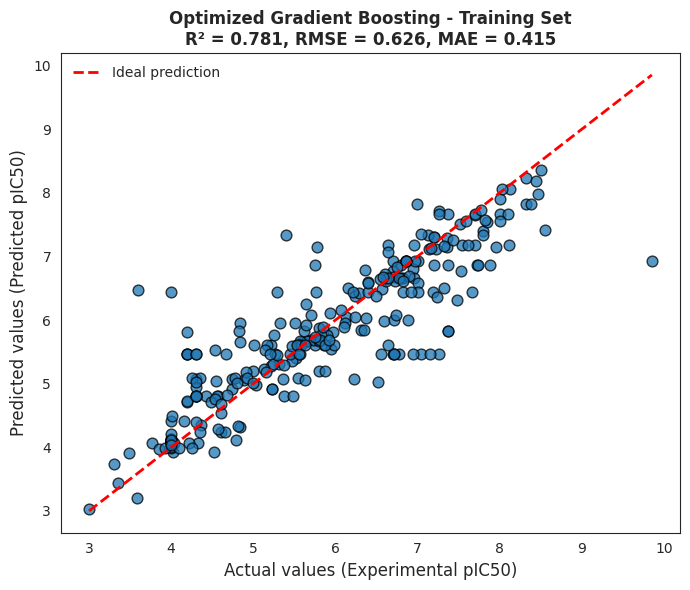

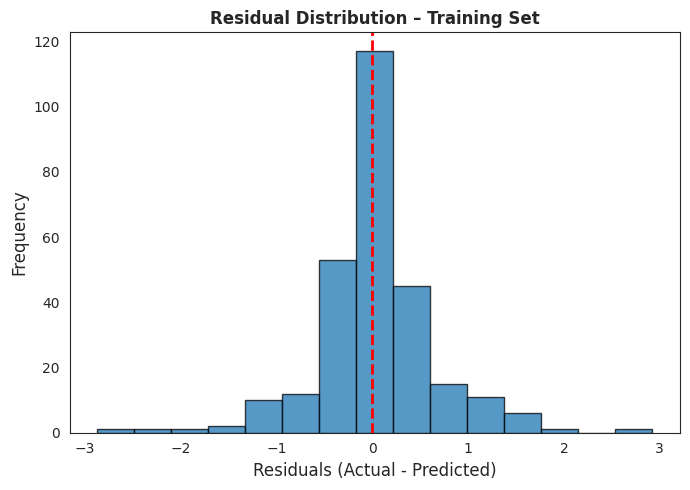


--- Testing Set Metrics ---
Mean squared error (MSE): 0.27
Coefficient of determination (R^2): 0.85
RMSE:                     0.5177
MAE:                      0.3377


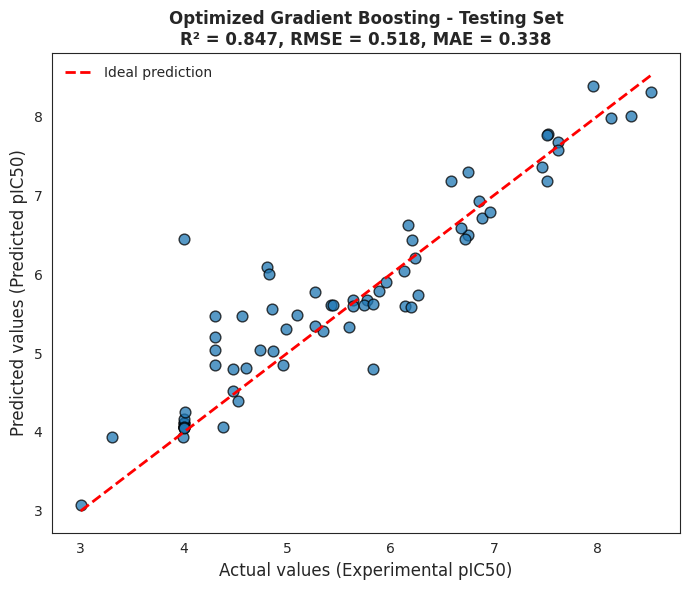

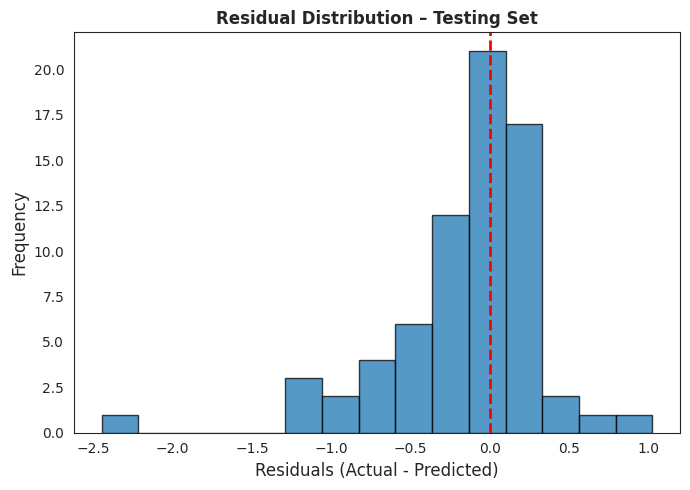

In [19]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# ==========================================
# 1. LOAD MODEL AND CURRENT FEATURES
# ==========================================
model = joblib.load("Keap1.pkl")
selected_features = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# Load original dataset
data = pd.read_csv(
    "bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv"
)

# Extract and align features/targets
X = data[selected_features].values.astype(np.float64)
Y = data["pIC50"].values

# Split data exactly how you did before training
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

Y_train = np.asarray(Y_train).ravel()
Y_test = np.asarray(Y_test).ravel()


# ==========================================
# 2. EVALUATION & PLOTTING FUNCTION
# ==========================================
def evaluate_and_plot(X_data, Y_true, set_label, filename_prefix):
    # Predict using your loaded model
    Y_pred = model.predict(X_data)

    # Calculate metrics
    r2 = r2_score(Y_true, Y_pred)
    rmse = np.sqrt(mean_squared_error(Y_true, Y_pred))
    mae = mean_absolute_error(Y_true, Y_pred)

    # Print to console using your exact preferred formats
    print(f"\n--- {set_label} Metrics ---")
    print("Mean squared error (MSE): %.2f" % mean_squared_error(Y_true, Y_pred))
    print("Coefficient of determination (R^2): %.2f" % r2_score(Y_true, Y_pred))
    print(f"RMSE:                     {rmse:.4f}")
    print(f"MAE:                      {mae:.4f}")

    # Plot 1: Predicted vs Actual
    plt.figure(figsize=(7, 6))
    plt.scatter(Y_true, Y_pred, alpha=0.75, s=60, edgecolors="black")

    # Dynamic limits for the identity line
    min_val = min(Y_true.min(), Y_pred.min())
    max_val = max(Y_true.max(), Y_pred.max())
    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        "r--",
        linewidth=2,
        label="Ideal prediction",
    )

    plt.xlabel("Actual values (Experimental pIC50)", fontsize=12)
    plt.ylabel("Predicted values (Predicted pIC50)", fontsize=12)
    plt.title(
        f"Optimized Gradient Boosting - {set_label}\nR² = {r2:.3f}, RMSE = {rmse:.3f}, MAE = {mae:.3f}",
        fontsize=12,
        fontweight="bold",
    )
    plt.legend(frameon=False)
    plt.grid(False)
    plt.tight_layout()
    plt.savefig(
        f"{filename_prefix}_predicted_vs_actual.png",
        dpi=600,
        bbox_inches="tight",
    )
    plt.show()

    # Plot 2: Residual distribution
    residuals = Y_true - Y_pred

    plt.figure(figsize=(7, 5))
    plt.hist(residuals, bins=15, edgecolor="black", alpha=0.75)
    plt.axvline(0, color="red", linestyle="--", linewidth=2)

    plt.xlabel("Residuals (Actual - Predicted)", fontsize=12)
    plt.ylabel("Frequency", fontsize=12)
    plt.title(
        f"Residual Distribution – {set_label}", fontsize=12, fontweight="bold"
    )
    plt.grid(False)
    plt.tight_layout()
    plt.savefig(
        f"{filename_prefix}_residuals.png", dpi=600, bbox_inches="tight"
    )
    plt.show()


# ==========================================
# 3. RUN EVALUATION FOR TRAIN & TEST
# ==========================================
# Evaluate Training Set
evaluate_and_plot(
    X_train, Y_train, set_label="Training Set", filename_prefix="Train"
)

# Evaluate Testing Set
evaluate_and_plot(
    X_test, Y_test, set_label="Testing Set", filename_prefix="Test"
)


## **6. Scatter Plot of Experimental vs Predicted pIC50 Values**

Saved complete feature importance rankings to keap1_feature_importances_all.csv!


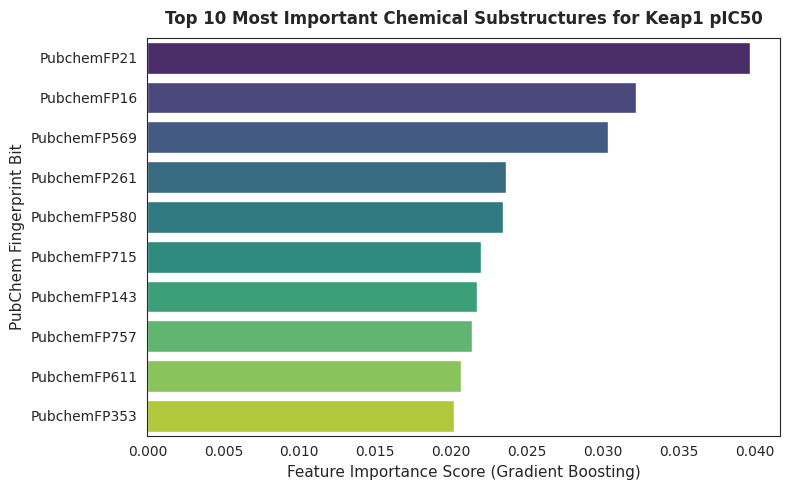

In [21]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ==========================================
# 1. LOAD MODEL AND SURVIVING FEATURES
# ==========================================
# Load your trained Gradient Boosting model
model = joblib.load("Keap1.pkl")

# Load the exact descriptors that survived your variance filter
surviving_columns = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# ==========================================
# 2. EXTRACT & SORT GRADIENT BOOSTING IMPORTANCES
# ==========================================
# Extract relative feature importances from your Gradient Boosting Regressor
importances = model.feature_importances_

# Map and sort features by their mathematical importance weight
feature_imp_df = pd.DataFrame(
    {"PubChem_Bit": surviving_columns, "Importance": importances}
).sort_values(by="Importance", ascending=False)

# Save the full importance metrics table for reference or spreadsheet usage
feature_imp_df.to_csv("keap1_feature_importances_all.csv", index=False)
print("Saved complete feature importance rankings to keap1_feature_importances_all.csv!")

# ==========================================
# 3. PLOT TOP 10 CHEMICAL FRAGMENTS
# ==========================================
plt.figure(figsize=(8, 5))

sns.barplot(
    x="Importance",
    y="PubChem_Bit",
    data=feature_imp_df.head(10),
    palette="viridis",
    hue="PubChem_Bit",
    legend=False,
)

plt.title(
    "Top 10 Most Important Chemical Substructures for Keap1 pIC50",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
plt.xlabel("Feature Importance Score (Gradient Boosting)", fontsize=11)
plt.ylabel("PubChem Fingerprint Bit", fontsize=11)

# Save the plot as a publication-ready 600 DPI PNG image
plt.tight_layout()
plt.savefig(
    "keap1_top10_feature_importance.png", dpi=600, bbox_inches="tight"
)
plt.show()


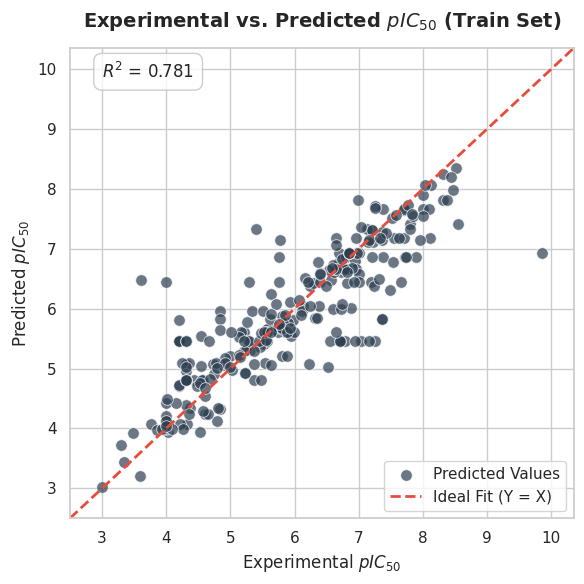

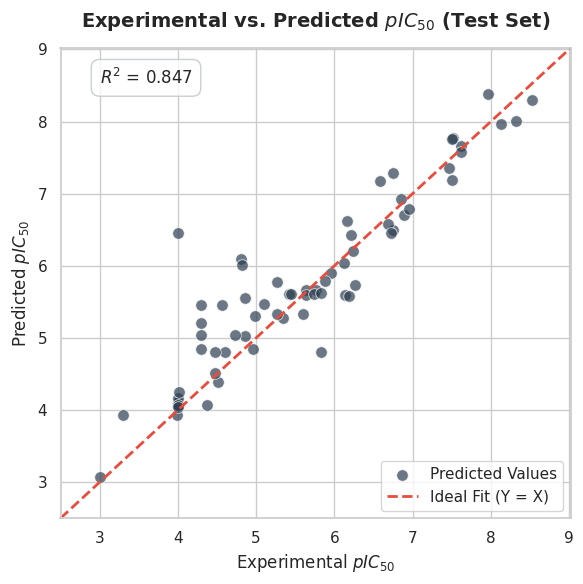

In [22]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

# ==========================================
# 1. LOAD MODEL AND CURRENT FEATURES
# ==========================================
model = joblib.load("Keap1.pkl")
selected_features = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# Load original dataset
data = pd.read_csv(
    "bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv"
)

# Extract and align features/targets
X = data[selected_features].values.astype(np.float64)
Y = data["pIC50"].values

# Split data exactly how you did before training
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

Y_train = np.asarray(Y_train).ravel()
Y_test = np.asarray(Y_test).ravel()


# ==========================================
# 2. PLOTTING FUNCTION (YOUR CLEAN LAYOUT STYLE)
# ==========================================
def generate_clean_square_plot(Y_true, Y_pred, set_label, filename):
    # Calculate R2 metric
    r2 = r2_score(Y_true, Y_pred)

    # Set the style for a clean, professional look
    sns.set_theme(style="whitegrid")

    plt.figure(figsize=(6, 6))

    # 1. Create the scatter plot using data parameters
    sns.scatterplot(
        x=Y_true,
        y=Y_pred,
        alpha=0.7,
        color="#2c3e50",
        edgecolor="w",
        s=70,
        label="Predicted Values",
    )

    # 2. Determine plot limits to make a perfect square
    min_val = min(Y_true.min(), Y_pred.min()) - 0.5
    max_val = max(Y_true.max(), Y_pred.max()) + 0.5
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)

    # 3. Add a diagonal reference line (Ideal Line: Y = X)
    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="#e74c3c",
        linestyle="--",
        linewidth=2,
        label="Ideal Fit (Y = X)",
    )

    # 4. Add the R² score automatically as a text box on the plot
    plt.text(
        min_val + 0.5,
        max_val - 0.5,
        f"$R^2$ = {r2:.3f}",
        fontsize=12,
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="#bdc3c7",
            boxstyle="round,pad=0.5",
        ),
    )

    # 5. Labels and Title
    plt.title(
        f"Experimental vs. Predicted $pIC_{{50}}$ ({set_label})",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )
    plt.xlabel("Experimental $pIC_{50}$", fontsize=12)
    plt.ylabel("Predicted $pIC_{50}$", fontsize=12)
    plt.legend(loc="lower right")
    plt.tight_layout()

    # Save the plot as a 600 DPI PNG image
    plt.savefig(filename, dpi=600, bbox_inches="tight")
    plt.show()


# ==========================================
# 3. RUN EVALUATION FOR TRAIN & TEST
# ==========================================
# Train Set Predictions & Plots
Y_pred_train = model.predict(X_train)
generate_clean_square_plot(
    Y_train,
    Y_pred_train,
    set_label="Train Set",
    filename="keap1_clean_experimental_vs_predicted_pIC50_TRAIN.png",
)

# Test Set Predictions & Plots
Y_pred_test = model.predict(X_test)
generate_clean_square_plot(
    Y_test,
    Y_pred_test,
    set_label="Test Set",
    filename="keap1_clean_experimental_vs_predicted_pIC50_TEST.png",
)


# **🎨 Fully Aesthetic Model Evaluation Plots**

**Scatter Plot (Experimental vs. Predicted)**

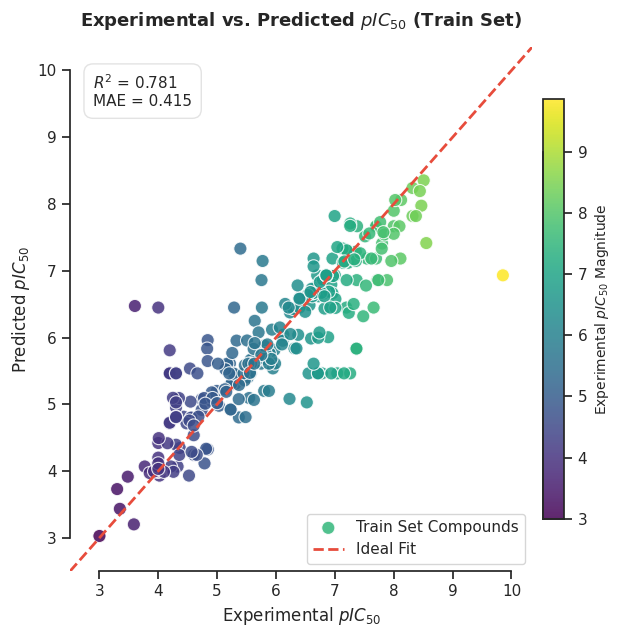

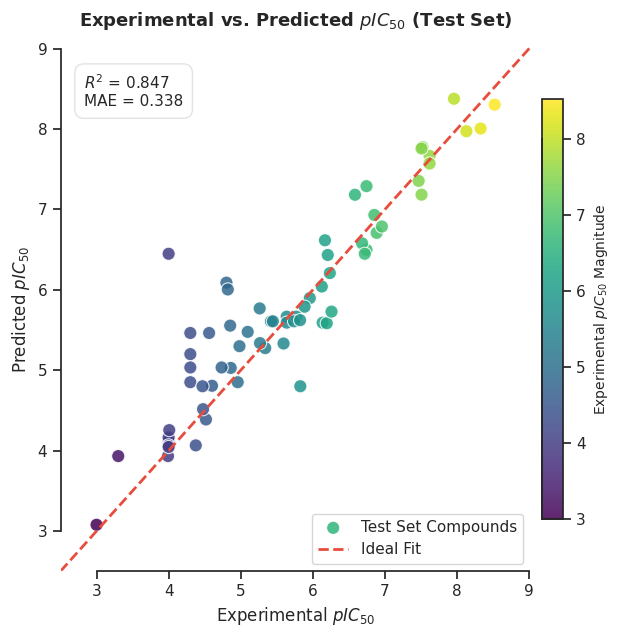

In [23]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

# ==========================================
# 1. LOAD MODEL AND CURRENT FEATURES
# ==========================================
model = joblib.load("Keap1.pkl")
selected_features = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# Load original dataset
data = pd.read_csv(
    "bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv"
)

# Extract and align features/targets
X = data[selected_features].values.astype(np.float64)
Y = data["pIC50"].values

# Split data exactly how you did before training
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

Y_train = np.asarray(Y_train).ravel()
Y_test = np.asarray(Y_test).ravel()


# ==========================================
# 2. PLOTTING FUNCTION (SCIENTIFIC TICK STYLE)
# ==========================================
def generate_scientific_plot(Y_true, Y_pred, set_label, filename):
    # Set clean scientific style parameters
    sns.set_theme(style="ticks")
    plt.rcParams.update(
        {
            "font.family": "sans-serif",
            "font.size": 11,
            "axes.labelsize": 12,
            "axes.titlesize": 13,
        }
    )

    plt.figure(figsize=(6.5, 6.5))

    # Create scatter plot where point colors map to the viridis palette based on values
    scatter = plt.scatter(
        Y_true,
        Y_pred,
        c=Y_true,
        cmap="viridis",
        alpha=0.85,
        edgecolor="white",
        linewidth=0.8,
        s=90,
        label=f"{set_label} Compounds",
    )

    # Create a dynamic perfect bounding box
    min_val = min(Y_true.min(), Y_pred.min()) - 0.5
    max_val = max(Y_true.max(), Y_pred.max()) + 0.5
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)

    # Add ideal fit diagonal line (Y = X)
    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="#e74c3c",
        linestyle="--",
        linewidth=2,
        label="Ideal Fit",
    )

    # Compute exact validation metrics
    r2 = r2_score(Y_true, Y_pred)
    mae = mean_absolute_error(Y_true, Y_pred)
    metric_text = f"$R^2$ = {r2:.3f}\nMAE = {mae:.3f}"

    # Place metrics box on plot using relative axes positioning (fixed top-left)
    plt.text(
        0.05,
        0.95,
        metric_text,
        transform=plt.gca().transAxes,
        verticalalignment="top",
        fontsize=11,
        bbox=dict(
            facecolor="white",
            alpha=0.9,
            edgecolor="#e0e0e0",
            boxstyle="round,pad=0.6",
        ),
    )

    # Add a colorbar on the side to reflect the viridis scaling
    cbar = plt.colorbar(scatter, pad=0.02, shrink=0.8)
    cbar.set_label("Experimental $pIC_{50}$ Magnitude", fontsize=10)

    # Typography & Axis layout tweaks
    plt.title(
        f"Experimental vs. Predicted $pIC_{{50}}$ ({set_label})",
        fontweight="semibold",
        pad=15,
    )
    plt.xlabel("Experimental $pIC_{50}$")
    plt.ylabel("Predicted $pIC_{50}$")
    plt.legend(loc="lower right", frameon=True)

    # Clean trim layout borders
    sns.despine(trim=True)
    plt.tight_layout()

    # Save out at highly reproducible 600 DPI resolution matrix
    plt.savefig(filename, dpi=600, bbox_inches="tight")
    plt.show()


# ==========================================
# 3. RUN EVALUATION FOR TRAIN & TEST
# ==========================================
# Train Set Predictions & Plots
Y_pred_train = model.predict(X_train)
generate_scientific_plot(
    Y_train,
    Y_pred_train,
    set_label="Train Set",
    filename="keap1_scientific_vs_predicted_pIC50_TRAIN.png",
)

# Test Set Predictions & Plots
Y_pred_test = model.predict(X_test)
generate_scientific_plot(
    Y_test,
    Y_pred_test,
    set_label="Test Set",
    filename="keap1_scientific_vs_predicted_pIC50_TEST.png",
)


**Residual Plot**

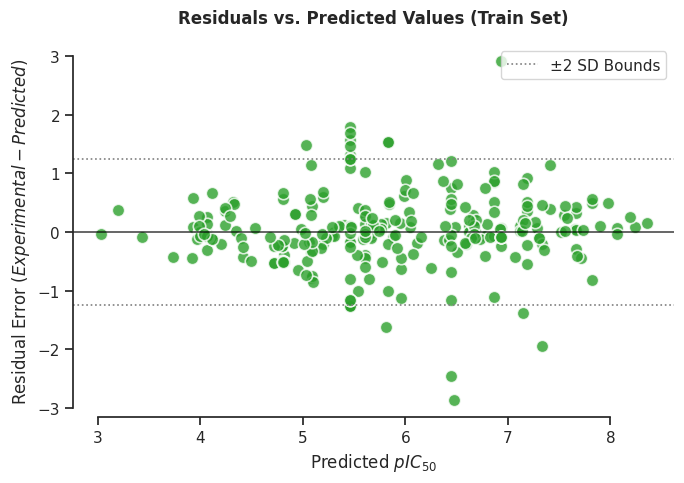

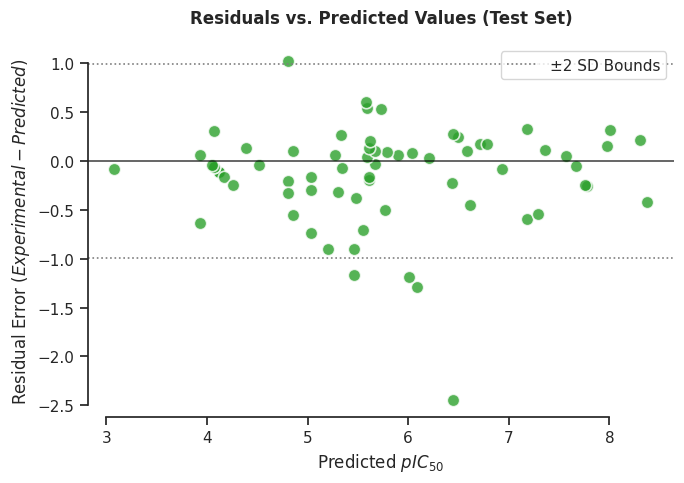

In [24]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

# ==========================================
# 1. LOAD MODEL AND CURRENT FEATURES
# ==========================================
model = joblib.load("Keap1.pkl")
selected_features = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# Load original dataset
data = pd.read_csv(
    "bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv"
)

# Extract and align features/targets
X = data[selected_features].values.astype(np.float64)
Y = data["pIC50"].values

# Split data exactly how you did before training
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

Y_train = np.asarray(Y_train).ravel()
Y_test = np.asarray(Y_test).ravel()


# ==========================================
# 2. PLOTTING FUNCTION (RESIDUAL DIAGNOSTICS STYLE)
# ==========================================
def generate_residual_scatter_plot(Y_true, Y_pred, set_label, filename):
    sns.set_theme(style="ticks")
    residuals = Y_true - Y_pred

    plt.figure(figsize=(7, 5))

    # Plot the residual scatter using your exact color and borders
    sns.scatterplot(
        x=Y_pred,
        y=residuals,
        alpha=0.8,
        color="#2ca02c",
        edgecolor="white",
        linewidth=1.2,
        s=80,
    )

    # Reference indicators
    plt.axhline(y=0, color="black", linestyle="-", linewidth=1.2, alpha=0.7)
    plt.axhline(
        y=2 * np.std(residuals),
        color="#7f7f7f",
        linestyle=":",
        linewidth=1.2,
        label="±2 SD Bounds",
    )
    plt.axhline(
        y=-2 * np.std(residuals), color="#7f7f7f", linestyle=":", linewidth=1.2
    )

    plt.title(
        f"Residuals vs. Predicted Values ({set_label})",
        fontweight="semibold",
        pad=15,
    )
    plt.xlabel("Predicted $pIC_{50}$")
    plt.ylabel("Residual Error ($Experimental - Predicted$)")
    plt.legend(loc="upper right", frameon=True)

    sns.despine(trim=True)
    plt.tight_layout()

    # Save the output figure at production standard 600 DPI
    plt.savefig(filename, dpi=600, bbox_inches="tight")
    plt.show()


# ==========================================
# 3. RUN EVALUATION FOR TRAIN & TEST
# ==========================================
# Train Set Residual Scatter Analysis
Y_pred_train = model.predict(X_train)
generate_residual_scatter_plot(
    Y_train,
    Y_pred_train,
    set_label="Train Set",
    filename="keap1_residual_vs_predicted_TRAIN.png",
)

# Test Set Residual Scatter Analysis
Y_pred_test = model.predict(X_test)
generate_residual_scatter_plot(
    Y_test,
    Y_pred_test,
    set_label="Test Set",
    filename="keap1_residual_vs_predicted_TEST.png",
)


**Residual Distribution Plot**

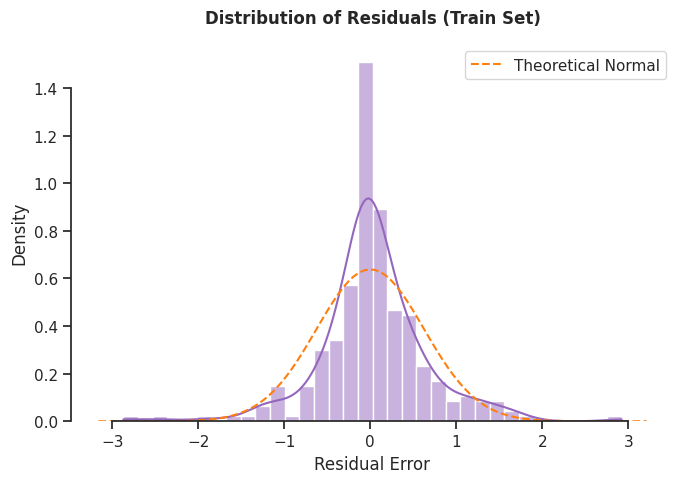

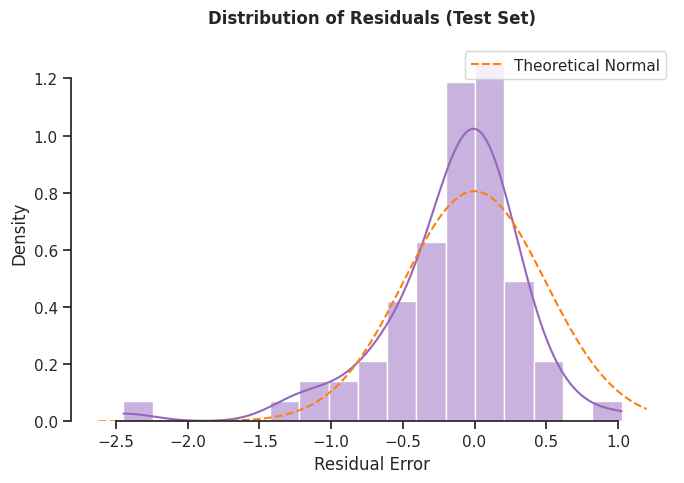

In [25]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import norm
from sklearn.model_selection import train_test_split

# ==========================================
# 1. LOAD MODEL AND CURRENT FEATURES
# ==========================================
model = joblib.load("Keap1.pkl")
selected_features = (
    pd.read_csv("descriptor_list.csv", header=None).squeeze("columns").tolist()
)

# Load original dataset
data = pd.read_csv(
    "bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv"
)

# Extract and align features/targets
X = data[selected_features].values.astype(np.float64)
Y = data["pIC50"].values

# Split data exactly how you did before training
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

Y_train = np.asarray(Y_train).ravel()
Y_test = np.asarray(Y_test).ravel()


# ==========================================
# 2. PLOTTING FUNCTION (RESIDUAL DISTRIBUTION STYLE)
# ==========================================
def generate_residual_distribution_plot(Y_true, Y_pred, set_label, filename):
    sns.set_theme(style="ticks")
    residuals = Y_true - Y_pred

    plt.figure(figsize=(7, 5))

    # Kernel Density Estimate combined with Histogram using your exact purple theme
    sns.histplot(
        residuals,
        kde=True,
        color="#9467bd",
        edgecolor="white",
        linewidth=1,
        stat="density",
    )

    # Overlay a theoretical normal distribution reference curve centered perfectly at 0
    xmin, xmax = plt.gca().get_xlim()
    x_axis = np.linspace(xmin, xmax, 100)
    plt.plot(
        x_axis,
        norm.pdf(x_axis, 0, np.std(residuals)),
        color="#ff7f0e",
        linestyle="--",
        label="Theoretical Normal",
    )

    plt.title(
        f"Distribution of Residuals ({set_label})", fontweight="semibold", pad=15
    )
    plt.xlabel("Residual Error")
    plt.ylabel("Density")
    plt.legend(loc="upper right", frameon=True)

    sns.despine(trim=True)
    plt.tight_layout()

    # Save the output figure at production standard 600 DPI
    plt.savefig(filename, dpi=600, bbox_inches="tight")
    plt.show()


# ==========================================
# 3. RUN EVALUATION FOR TRAIN & TEST
# ==========================================
# Train Set Residual Error Distribution Analysis
Y_pred_train = model.predict(X_train)
generate_residual_distribution_plot(
    Y_train,
    Y_pred_train,
    set_label="Train Set",
    filename="keap1_residual_distribution_TRAIN.png",
)

# Test Set Residual Error Distribution Analysis
Y_pred_test = model.predict(X_test)
generate_residual_distribution_plot(
    Y_test,
    Y_pred_test,
    set_label="Test Set",
    filename="keap1_residual_distribution_TEST.png",
)


# Save Model as Pickle Object

In [ ]:
import pickle

In [ ]:
pickle.dump(model, open('acetylcholinesterase_model.pkl', 'wb'))